# Nearest centroid y K-Nearest Neightbors
En esta practica analizamos dos algoritmos de clasificación supervizada `KC` y `KNN`.

La idea de estos algoritmos es trabajar con datos que ya conocemos sus etiquetas para predecir la etiqueta de nuevos datos. 
Trabajaremos inicialmente con un conjunto de datos sintético generado mediante `make_blobs`, configurado para producir tres
clases, esto permitirá trabajar en un entorno controlado.

La idea intuitiva de estos algorimtos es la siguiente:

## Nearest Centroids
Se calcula la distancia a los centroides de cada clase y se asigna la etiqueta del centroide más cercano.

## K-Nearest Neightbors
Se calcula los K puntos más cercanos y se asigna la etiqueta que más se repite entre esos K puntos.

Implemente los dos algoritmos y estos serán los que se usen las pruebas. 

In [19]:
import numpy as np 
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

## Generación y exploración de datos

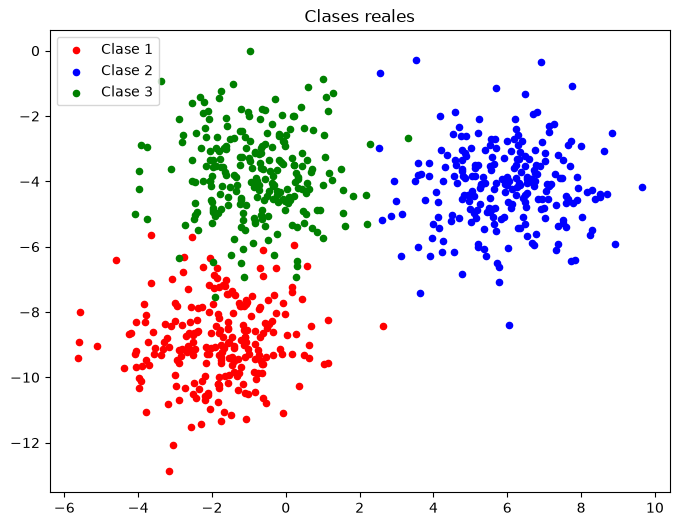

In [39]:
## Generación y exploración de datos 
X, y = make_blobs(n_samples=700, n_features=2, cluster_std=1.3, random_state=40)
#visualizacion
colores = ['red', 'blue', 'green']
clases = ['Clase 1', 'Clase 2', 'Clase 3']

plt.figure(figsize=(8, 6))
plt.title('Clases reales')

for clase_id in np.unique(y):
    #solo los puntos que pertenecen a esta clase
    mascara = (y == clase_id)
    plt.scatter(X[mascara, 0], X[mascara, 1], color=colores[clase_id], label=clases[clase_id], s=20)

plt.legend()
plt.show()

## Separacion de datos 
Se dividen los datos en un 80% entrenamiento y 20% de prueba, la division se hace de forma aleatoria dentro del conjunto de datos. 
La importancia de dividir los datos de esta forma es para evitar sobre entremiento. Si usaramos los mismos datos para entrenar y evaluar, el modelo estaria "memorizando" los datos. Por lo que en la etapa de prueba necesitamos pasarle datos que no conozca el modelo.

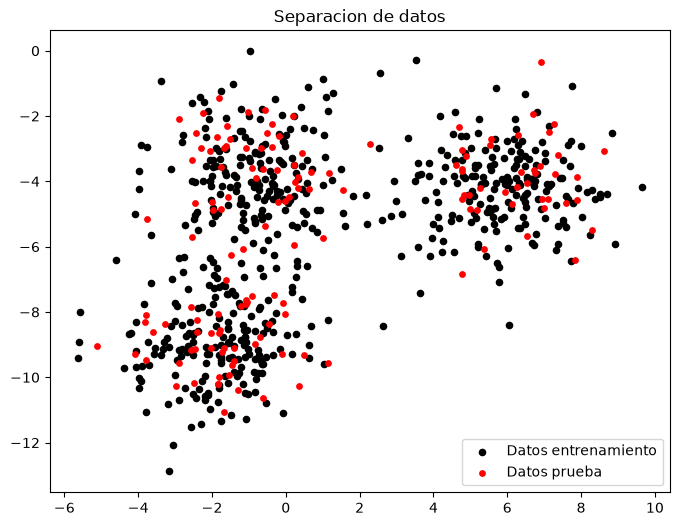

In [40]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
clases = ['Train set', 'Test set']

plt.figure(figsize=(8, 6))
plt.title('Separacion de datos')
plt.scatter(X_train[:, 0], X_train[:, 1], color = 'black', label = 'Datos entrenamiento', s=20)
plt.scatter(X_test[:, 0], X_test[:, 1], color = 'red', label = 'Datos prueba', s=15)
plt.legend()
plt.show()


## Nearest Centroid

In [48]:
class NearestCentroid:
    def __init__(self):
        self.X = None
        self.y = None
        self.clases = None
        self.centroides = None


    def fit(self, X, y):
        self.X = np.array(X)
        self.y = np.array(y)

        N = len(self.y) #total de datos
        clases, contadores = np.unique(self.y, return_counts=True)  #cuantos elementos tiene cada clase
        self.clases = clases
        

        #encontramos los puntos en cada clase y obtenemos la media (centroides)
        centroides = np.zeros((len(clases), 2))
        for i, id in enumerate(np.unique(y)):
            mascara = y == id
            centroides[i][0], centroides[i][1] = np.mean(self.X[mascara], axis = 0)

        self.centroides = centroides
        return self
    
    def predecir(self, x):
        #calculamos la distancia a todos los centroides y asignamos el minimo
        distancias = np.linalg.norm(self.centroides - x, axis=1)
        etiqueta = np.argmin(distancias) 

        return etiqueta

In [89]:
NC = NearestCentroid()
NC.fit(X_train, y_train)
centroides = NC.centroides
etiquetas_predichas = [NC.predecir(X_test[i]) for i in range(len(X_test))]

accuracy = np.mean(y_test == etiquetas_predichas)
print(f'El accuracy es de {accuracy}')

El accuracy es de 0.9857142857142858


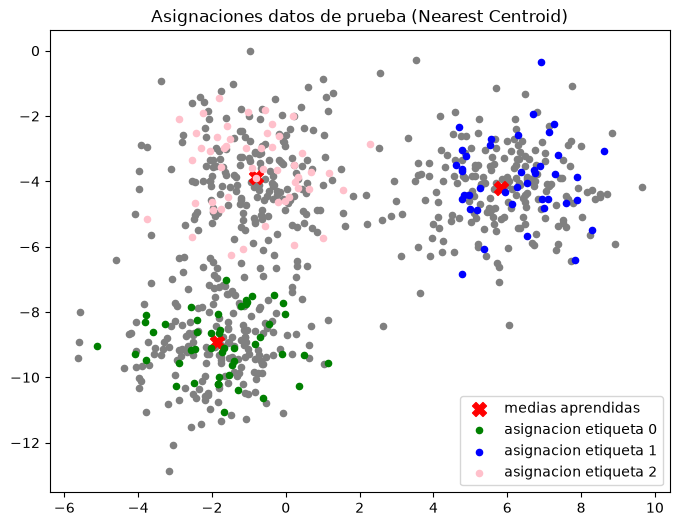

In [90]:
#grafico con las medias aprendidas
colores = ['green', 'blue', 'pink']
plt.figure(figsize=(8, 6))
plt.scatter(X_train[:, 0], X_train[:, 1], color='gray', s=20)
plt.scatter(centroides[:, 0], centroides[:, 1], color = 'red', marker='X', label = 'medias aprendidas', s = 100)
for clase_id in np.unique(y_test):
    #solo los puntos que pertenecen a esta clase
    mascara = (etiquetas_predichas == clase_id)
    plt.scatter(X_test[mascara, 0], X_test[mascara, 1], color=colores[clase_id], s=20, label = f'asignacion etiqueta {clase_id}')
plt.title(f"Asignaciones datos de prueba (Nearest Centroid)")
plt.legend()
plt.show()

### Analisis
Podemos notar que el algoritmo encontre 3 centroides de forma correcta (media de cada clase). Una vez encontrados los centroides lo unico que se hace para predecir nuevos valores es calcular la distancia del punto (que buscamos predecir) a los centroides encontrados, y asignamos la etiqueta del centroide más cercano. 
El modelo clasifico de gran forma los datos de prueba, equivocandose solo en muy pocos puntos que seguramente fueron los que se encontraban en las orillas.

## K-Nearest Neightbors

In [83]:
class KNN:
    def __init__(self, k: int):
        self.k = k
        self.X = None
        self.y = None
        self.clases = None

    def fit(self, X, y):
        self.X = np.array(X)
        self.y = np.array(y)
        self.clases = np.unique(y)
        return self

    def predecir(self, x):
        #distancia a todos los puntos
        distancias = np.linalg.norm(self.X - x, axis = 1)

        # k vecinos mas cercanos 
        k_vecinos = np.argpartition(distancias, self.k)[:self.k]

        #etiqueta de los vecinos y contar cuantas veces se repite cada clase
        id_vecinos = self.y[k_vecinos]
        valores, contador = np.unique(id_vecinos, return_counts=True)

        #asignamos la clase que se repite más
        asignacion = valores[np.argmax(contador)]
        return asignacion
    

In [87]:
knn = KNN(k = 3)
knn.fit(X_train, y_train)
etiquetas_predichas_knn = [knn.predecir(X_test[i]) for i in range(len(X_test))]

acc = np.mean(y_test == etiquetas_predichas_knn)
print(f'Las clases encontradas son {np.unique(etiquetas_predichas_knn)}')
print(f'El accuracy es de {acc}')

Las clases encontradas son [0 1 2]
El accuracy es de 0.9857142857142858


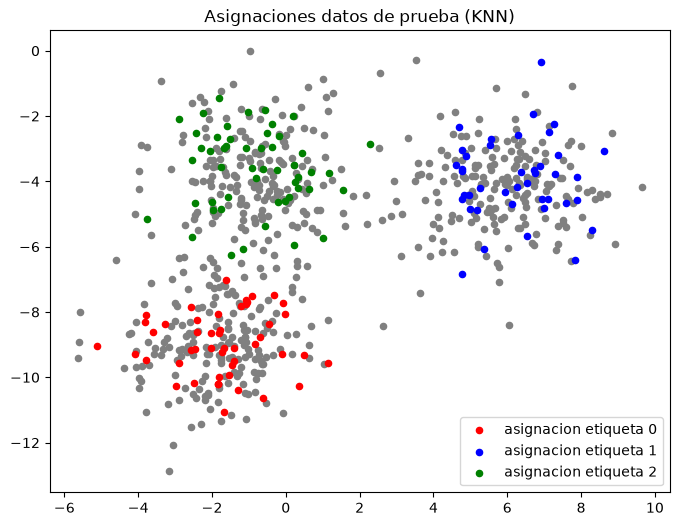

In [ ]:
#grafico
colores = ['red', 'blue', 'green']
plt.figure(figsize=(8, 6))
plt.scatter(X_train[:, 0], X_train[:, 1], color='gray', s=20)

for clase_id in np.unique(etiquetas_predichas_knn):
    #solo los puntos que pertenecen a esta clase
    mascara = (etiquetas_predichas_knn == clase_id)
    plt.scatter(X_test[mascara, 0], X_test[mascara, 1], color=colores[clase_id], s=20, label = f'asignacion etiqueta {clase_id}')
plt.title(f"Asignaciones datos de prueba (KNN)")
plt.legend()
plt.show()

### Analisis
KNN considera bolas centradas en los puntos que buscamos predecir y lo que hace es asignar la etiqueta que más se repite (de los puntos de entrenamiento dentro de la bola).
El parametro k es el numero de puntos de entrenamiento que vamos a considerar dentro de la bola. 

Al igual que con nearest centroid tenemos un gran accuracy por lo que los dos modelos estan funcionando de buena manera.

## Efecto del parametro K
Ahora vamos a variar al parametro K de KNN para ver el efecto en los resultados del modelo.

El accuracy con k = 1 es 0.9785714285714285
El accuracy con k = 3 es 0.9857142857142858
El accuracy con k = 5 es 0.9857142857142858
El accuracy con k = 7 es 0.9857142857142858
El accuracy con k = 9 es 0.9857142857142858
El accuracy con k = 15 es 0.9785714285714285


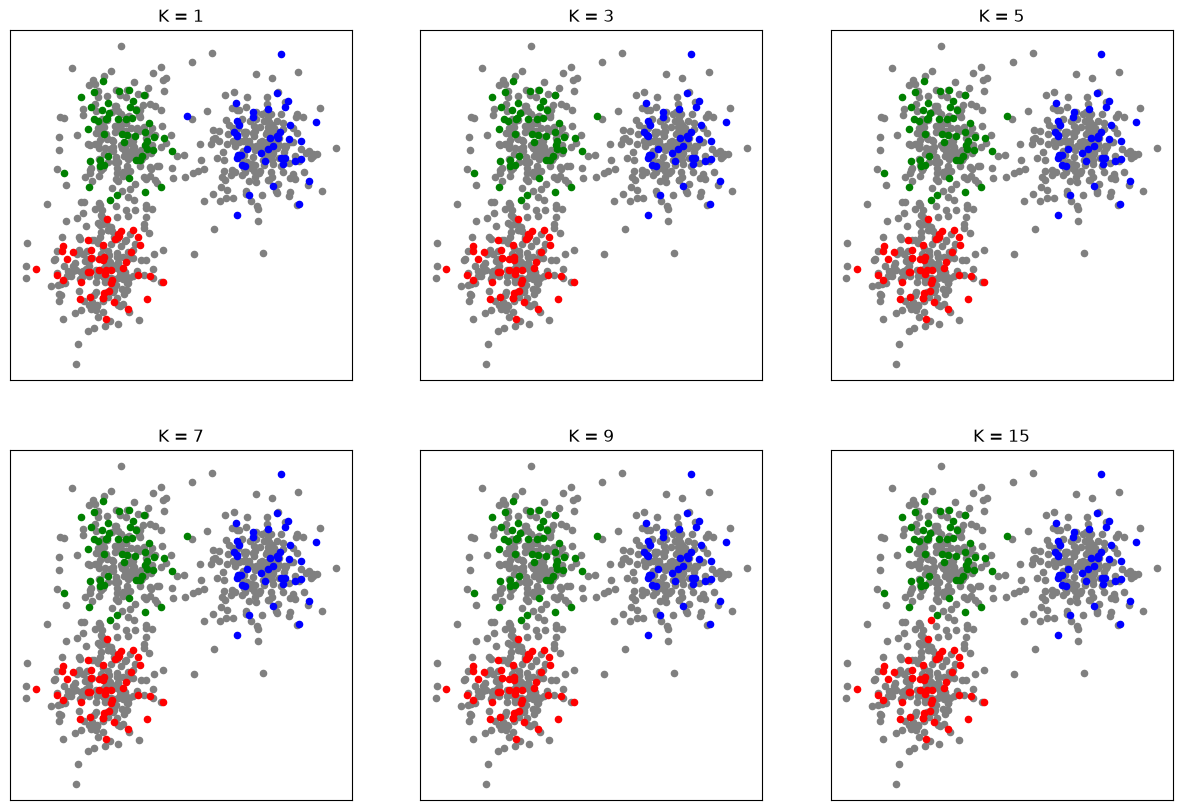

In [108]:
Ks = [1, 3, 5, 7, 9, 15]

fig, ax = plt.subplots(2, 3, figsize = (15, 10))
ax = ax.flatten()
for i, k in enumerate(Ks):
    knn_i = KNN(k = k)
    knn_i.fit(X_train, y_train)
    etiquetas = [knn_i.predecir(X_test[i]) for i in range(len(X_test))]

    acc = np.mean(y_test == etiquetas)
    colores = ['red', 'blue', 'green']

    ax[i].scatter(X_train[:, 0], X_train[:, 1], color='gray', s=20)

    for clase_id in np.unique(etiquetas):
    #solo los puntos que pertenecen a esta clase
        mascara = (etiquetas == clase_id)
        ax[i].scatter(X_test[mascara, 0], X_test[mascara, 1], color=colores[clase_id], s=20, label = f'asignacion etiqueta {clase_id}')
        ax[i].set_title(f'K = {k}')
        ax[i].set_xticks([])
        ax[i].set_yticks([])
    
    print(f'El accuracy con k = {k} es {acc}')

plt.show()
    

El algoritmo funciona bastante bien aunque se varie el parametro de K. Los puntos mal asignados es muuy parecido en cada caso y solo se confunde cuando estan muy cerca los puntos

## Comparacion final 
| Algoritmo | Parametro | Exactitud |
|:---|:---:|---:|
| Nearest centroid | Ninguno| 0.9857142857142858 | 
| K-nearest neightbors | K (puntos en la bola) | 0.9857142857142858 | 